# Lab 3, Notebook B — Kernel ridge regression

*Linear Algebra for Data Science, UCU 2026. Uses Session 4.2 (kernels, the representer theorem, kernel ridge) and Session 4.1 (Cholesky).*

A kernel $k(\mathbf{x},\mathbf{y}) = \langle\phi(\mathbf{x}),\phi(\mathbf{y})\rangle$ is an inner product in a feature space $\mathcal{F}$ that you never construct. By the representer theorem, ridge regression in $\mathcal{F}$ has a solution $f(\mathbf{x}) = \sum_i\alpha_i k(\mathbf{x}_i,\mathbf{x})$ with

$$(K + \lambda I)\,\boldsymbol\alpha = \mathbf{y},\qquad K_{ij} = k(\mathbf{x}_i,\mathbf{x}_j).$$

$K+\lambda I$ is symmetric positive definite for every kernel and every $\lambda>0$, so one Cholesky factorization solves the problem. The cost depends on $n$, not on $\dim\mathcal{F}$. In this notebook you check the kernel trick, see what $\lambda$ does to the conditioning, and measure the cost.

**How to work.** As in Notebook A: **predict in writing, then compute, then explain any difference.**

**Rules.**
- Inside the functions you implement, do not call `np.linalg.inv` or `sklearn`'s `KernelRidge`. Use `KernelRidge` and `GaussianProcessRegressor` only where a cell says **check**.
- You may use `scipy.linalg.cholesky`, `cho_factor`/`cho_solve`, `solve_triangular` and `np.linalg.eigvalsh`.
- Do not change the seeds.
- Before you submit, run `Kernel → Restart & Run All`.

**Marking.** Core B is worth 2 points at the defence; the code point and the extension are shared with Notebook A.

**Contents.** B1 The solver · B2 The kernel trick, checked · B3 The Gaussian kernel and the role of $\lambda$ · B4 Cost and scale · Extension E3 (GP regression). Attempt **at most one** extension in the whole lab.

| | |
|---|---|
| **Team member 1** | *Ihor, Kashuba* |
| **Team member 2** | *Vladyslav, Hryhola* |
| **Extension attempted** (at most one in the whole lab) | *E3* |
| **Late days used on this lab** | *0* |
| **Runs top to bottom from a clean kernel** | *yes* |

In [1]:
import sys, time
from math import comb
import numpy as np
import scipy, scipy.linalg as sl
import matplotlib, matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import make_friedman1
from sklearn.preprocessing import PolynomialFeatures

print("python", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| matplotlib", matplotlib.__version__, "| sklearn", sklearn.__version__)

python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | matplotlib 3.10.0 | sklearn 1.6.1


**Data.** Friedman's benchmark #1: ten features uniform on $[0,1]$, of which only five matter, through
$y = 10\sin(\pi x_1x_2) + 20(x_3-\tfrac12)^2 + 10x_4 + 5x_5 + \text{noise}$, with noise standard deviation 1. It is synthetic, but nonlinear in a way a linear model cannot capture, which is the point of a kernel.

We split 1000 points into 500 for training, 250 for validation and 250 for testing. We standardise the features with **training** statistics only, and centre $y$ by its training mean: kernel ridge has no intercept, so predictions are of the centred $y$ (add the mean back to report them in the original units).

In [2]:
X_all, y_all = make_friedman1(n_samples=1000, noise=1.0, random_state=0)
mu_x, sd_x = X_all[:500].mean(axis=0), X_all[:500].std(axis=0)
X_all = (X_all - mu_x) / sd_x
y_mean = y_all[:500].mean()
Xtr, Xva, Xte = X_all[:500], X_all[500:750], X_all[750:]
ytr, yva, yte = y_all[:500] - y_mean, y_all[500:750] - y_mean, y_all[750:] - y_mean
print(Xtr.shape, Xva.shape, Xte.shape)

def mse(a, b):
    return np.mean((a - b) ** 2)

(500, 10) (250, 10) (250, 10)


---
## B1. The solver

Implement:
- `k_poly(X, Y, d, c)`, the matrix of $(c + \mathbf{x}^\top\mathbf{y})^d$ over the rows of `X` and `Y`;
- `k_gauss(X, Y, sigma)`, the matrix of $\exp(-\|\mathbf{x}-\mathbf{y}\|^2/(2\sigma^2))$. Use $\|\mathbf{x}-\mathbf{y}\|^2 = \|\mathbf{x}\|^2+\|\mathbf{y}\|^2-2\mathbf{x}^\top\mathbf{y}$, with no Python loops over points, and clip tiny negative values caused by rounding to zero;
- `krr_fit(K, y, lam)`, which returns $\boldsymbol\alpha$ solving $(K+\lambda I)\boldsymbol\alpha = \mathbf{y}$ by one Cholesky factorization, leaving `K` unchanged;
- `krr_predict(K_test_train, alpha)`.

In [3]:
def k_poly(X, Y, d, c):
    return (c + X @ Y.T) ** d

def k_gauss(X, Y, sigma):
    x_sq = np.sum(X ** 2, axis=1, keepdims=True)
    y_sq = np.sum(Y ** 2, axis=1, keepdims=True).T
    sq_dist = np.clip(x_sq + y_sq - 2.0 * (X @ Y.T), 0.0, None)
    return np.exp(-sq_dist / (2.0 * sigma ** 2))

def krr_fit(K, y, lam):
    L, lower = sl.cho_factor(K + lam * np.eye(len(K)), lower=True)
    return sl.cho_solve((L, lower), y)

def krr_predict(K_test_train, alpha):
    return K_test_train @ alpha

In [4]:
# check against scikit-learn on 200 training points (sklearn calls lam 'alpha', and uses gamma = 1/(2 sigma^2))
from sklearn.kernel_ridge import KernelRidge
sigma, lam = 4.0, 0.1
a = krr_fit(k_gauss(Xtr[:200], Xtr[:200], sigma), ytr[:200], lam)
mine = krr_predict(k_gauss(Xva, Xtr[:200], sigma), a)
ref = KernelRidge(alpha=lam, kernel="rbf", gamma=1 / (2 * sigma ** 2)).fit(Xtr[:200], ytr[:200]).predict(Xva)
print("max difference from sklearn:", np.abs(mine - ref).max())
assert np.allclose(mine, ref)

max difference from sklearn: 1.5987211554602254e-13


---
## B2. The kernel trick, checked

**(a)** For the polynomial kernel $(1+\mathbf{x}^\top\mathbf{y})^2$ on $\mathbb{R}^{10}$, write the explicit feature map `phi_poly2(X)` with $\phi(\mathbf{x})^\top\phi(\mathbf{y}) = (1+\mathbf{x}^\top\mathbf{y})^2$. Expand the square to find the entries, minding the $\sqrt2$ factors. How many features are there? Check against `k_poly`.

In [5]:
def phi_poly2(X):
    n, p = X.shape
    ones = np.ones((n, 1))
    lin = np.sqrt(2.0) * X
    sq = X ** 2
    idx_i, idx_j = np.triu_indices(p, k=1)
    cross = np.sqrt(2.0) * (X[:, idx_i] * X[:, idx_j])
    return np.hstack([ones, lin, sq, cross])

Phi_tr, Phi_te = phi_poly2(Xtr), phi_poly2(Xte)
print("dim F =", Phi_tr.shape[1])
# check
assert np.allclose(Phi_tr[:50] @ Phi_te[:40].T, k_poly(Xtr[:50], Xte[:40], 2, 1))

dim F = 66


**Your answer.** Expanding the square for $\mathbf{x}, \mathbf{y} \in \mathbb{R}^{10}$ gives:
$$(1 + \mathbf{x}^\top\mathbf{y})^2 = 1 + 2\sum_{i=1}^{10} x_i y_i + \left(\sum_{i=1}^{10} x_i y_i\right)^2 = 1 + \sum_{i=1}^{10} (\sqrt{2}x_i)(\sqrt{2}y_i) + \sum_{i=1}^{10} x_i^2 y_i^2 + \sum_{1 \le i < j \le 10} (\sqrt{2}x_i x_j)(\sqrt{2}y_i y_j).$$
Thus, the explicit feature map $\phi(\mathbf{x})$ consists of:
- $1$ constant feature ($1$),
- $10$ linear features ($\sqrt{2}x_i$ for $i=1,\dots,10$),
- $10$ pure quadratic features ($x_i^2$ for $i=1,\dots,10$), and
- $\binom{10}{2} = 45$ cross-product features ($\sqrt{2}x_i x_j$ for $1 \le i < j \le 10$).

In total, there are $D = \dim\mathcal{F} = 1 + 10 + 10 + 45 = \binom{10+2}{2} = 66$ features.

**(b)** Fit ordinary ridge regression on the features: $\mathbf{w}$ solving $(\Phi^\top\Phi+\lambda I)\mathbf{w} = \Phi^\top\mathbf{y}$, by Cholesky, with **no separate intercept** and $\lambda = 1$. Compare its test predictions $\Phi_{\text{test}}\mathbf{w}$ with kernel ridge using `k_poly(·,·,2,1)` and the same $\lambda$. Explain why they agree, citing the representer theorem.

In [6]:
lam = 1.0
G = Phi_tr.T @ Phi_tr + lam * np.eye(Phi_tr.shape[1])
w = sl.cho_solve(sl.cho_factor(G, lower=True), Phi_tr.T @ ytr)
pred_feat = Phi_te @ w

alpha_poly = krr_fit(k_poly(Xtr, Xtr, 2, 1), ytr, lam)
pred_kern = krr_predict(k_poly(Xte, Xtr, 2, 1), alpha_poly)

print("max |feature route - kernel route| =", np.abs(pred_feat - pred_kern).max())
print("test MSE, degree-2 polynomial model:", mse(pred_kern, yte))

max |feature route - kernel route| = 1.1368683772161603e-12
test MSE, degree-2 polynomial model: 2.4789639129689816


**Your answer.** The two routes agree to machine precision because they solve the exact same regularized least-squares problem in the feature space $\mathcal{F}$:
$$\min_{\mathbf{w} \in \mathcal{F}} \|\Phi\mathbf{w} - \mathbf{y}\|_2^2 + \lambda \|\mathbf{w}\|_2^2.$$
By the **representer theorem**, any component of $\mathbf{w}$ orthogonal to the row space of $\Phi$ (the span of the training feature vectors $\{\phi(\mathbf{x}_i)\}_{i=1}^n$) does not affect the training predictions $\Phi\mathbf{w}$ but strictly increases the ridge penalty $\lambda\|\mathbf{w}\|_2^2$. Therefore, the optimal weight vector must lie in the span of the training features, $\mathbf{w} = \Phi^\top\boldsymbol\alpha$, where $\boldsymbol\alpha = (K + \lambda I_n)^{-1}\mathbf{y}$ and $K = \Phi\Phi^\top$ (matching the algebraic push-through identity $(\Phi^\top\Phi + \lambda I_D)^{-1}\Phi^\top = \Phi^\top(\Phi\Phi^\top + \lambda I_n)^{-1}$). Consequently, the feature-route prediction $\Phi_{\text{test}}\mathbf{w} = \Phi_{\text{test}}\Phi^\top\boldsymbol\alpha = K_{\text{test,train}}\boldsymbol\alpha$ is identical to the kernel-route prediction.

**(c)** *Predict, then compute.* Count the flops of each route as functions of $n$, $p = 10$ and $D = \dim\mathcal{F}$:
- **feature route**: form $\Phi^\top\Phi$, about $nD^2$, plus a Cholesky, about $D^3/3$;
- **kernel route**: form $K$, about $n^2p$, plus a Cholesky, about $n^3/3$.

For degree $d$ on $\mathbb{R}^{10}$, $D = \binom{10+d}{d}$. *Predict* the degree at which the feature route becomes more expensive at $n=500$. Then time both for $d = 2,3,4,5$. For timing only, use `PolynomialFeatures(d)` to build a feature matrix of the right size; its weights differ from the exact $\phi$, which does not matter for the cost.

**Your prediction** *(write it before running the next cell)*:
At $n = 500$ and $p = 10$, the kernel route cost is independent of the degree $d$:
$$\text{flops}_{\text{kern}} \approx n^2 p + \frac{n^3}{3} = 500^2 \times 10 + \frac{500^3}{3} \approx 2.5\times 10^6 + 4.17\times 10^7 \approx 4.4\times 10^7\text{ flops}.$$
For the feature route, $D = \binom{10+d}{d}$ and $\text{flops}_{\text{feat}} \approx nD^2 + D^3/3$:
- $d = 2$: $D = \binom{12}{2} = 66 \implies \text{flops}_{\text{feat}} \approx 500(66^2) + 66^3/3 \approx 2.3\times 10^6$ flops (cheaper than kernel).
- $d = 3$: $D = \binom{13}{3} = 286 \implies \text{flops}_{\text{feat}} \approx 500(286^2) + 286^3/3 \approx 4.9\times 10^7$ flops (slightly exceeds kernel flops).
- $d = 4$: $D = \binom{14}{4} = 1001 \implies \text{flops}_{\text{feat}} \approx 500(1001^2) + 1001^3/3 \approx 8.4\times 10^8$ flops ($\sim 19\times$ more expensive).
- $d = 5$: $D = \binom{15}{5} = 3003 \implies \text{flops}_{\text{feat}} \approx 500(3003^2) + 3003^3/3 \approx 1.4\times 10^{10}$ flops ($\sim 306\times$ more expensive).

Thus, in flop count the feature route already slightly overtakes the kernel route at **$d = 3$** ($4.9\times 10^7 > 4.4\times 10^7$), and becomes dramatically more expensive in both flops and wall-clock time at **$d \ge 4$** (where $D > n$).

In [7]:
def best_time(f, repeat=3):
    best = np.inf
    for _ in range(repeat):
        t0 = time.perf_counter(); f(); best = min(best, time.perf_counter() - t0)
    return best

def feature_route(d):
    P = PolynomialFeatures(d).fit_transform(Xtr)
    G = P.T @ P + np.eye(P.shape[1])
    return sl.cho_solve(sl.cho_factor(G, lower=True), P.T @ ytr)

n = len(Xtr)
feature_route(2); krr_fit(k_poly(Xtr, Xtr, 2, 1.0), ytr, 1.0)      # warm-up: first calls carry one-off overheads
for d in [2, 3, 4, 5]:
    D = comb(10 + d, d)
    flops_feat, flops_kern = n * D ** 2 + D ** 3 / 3, n ** 2 * 10 + n ** 3 / 3
    t_feat = best_time(lambda: feature_route(d))
    t_kern = best_time(lambda: krr_fit(k_poly(Xtr, Xtr, d, 1.0), ytr, 1.0))
    print(f"d = {d}: D = {D:5d} | predicted flops feature {flops_feat:.1e}, kernel {flops_kern:.1e} | "
          f"time feature {1e3*t_feat:8.1f} ms, kernel {1e3*t_kern:6.1f} ms")

d = 2: D =    66 | predicted flops feature 2.3e+06, kernel 4.4e+07 | time feature     13.0 ms, kernel  140.3 ms
d = 3: D =   286 | predicted flops feature 4.9e+07, kernel 4.4e+07 | time feature     40.0 ms, kernel   39.1 ms
d = 4: D =  1001 | predicted flops feature 8.4e+08, kernel 4.4e+07 | time feature    243.6 ms, kernel   54.4 ms
d = 5: D =  3003 | predicted flops feature 1.4e+10, kernel 4.4e+07 | time feature   1370.6 ms, kernel   25.1 ms


**Your answer.** The timing measurements confirm the asymptotic prediction:
- The **kernel route** flop count ($4.4\times 10^7$) is independent of $d$, so after an initial transient spike at $d = 2$ ($140.3\text{ ms}$), its runtime stays flat around $25.1\text{–}54.4\text{ ms}$ for $d \in \{3, 4, 5\}$ because forming $K$ ($\sim n^2 p$) and factoring $K + \lambda I$ ($\sim n^3/3$) depend only on $n = 500$ and $p = 10$, not on $D = \dim\mathcal{F}$.
- The **feature route** is much faster at $d = 2$ ($D = 66 \ll n = 500$, taking $13.0\text{ ms}$ vs. $140.3\text{ ms}$), reaches the exact crossover point at $d = 3$ ($D = 286$, where its flop count $4.9\times 10^7$ just passes the kernel route's $4.4\times 10^7$ and the runtimes match at $40.0\text{ ms}$ vs. $39.1\text{ ms}$), becomes $4.5\times$ slower at $d = 4$ ($D = 1001$, $243.6\text{ ms}$ vs. $54.4\text{ ms}$), and blows up at $d = 5$ ($D = 3003$, $1370.6\text{ ms}$ vs. $25.1\text{ ms}$, or $\sim 55\times$ slower) as $nD^2 + D^3/3$ grows combinatorially.

---
## B3. The Gaussian kernel and the role of $\lambda$

First choose $\sigma$ by a short search on the validation set, with $\lambda = 10^{-2}$ fixed.

In [8]:
sigmas = [1, 2, 3, 4, 6, 8]
val_err = []
for s in sigmas:
    a = krr_fit(k_gauss(Xtr, Xtr, s), ytr, 1e-2)
    val_err.append(mse(krr_predict(k_gauss(Xva, Xtr, s), a), yva))
sigma = sigmas[int(np.argmin(val_err))]
print("validation MSE:", dict(zip(sigmas, np.round(val_err, 3))), "-> sigma =", sigma)
K = k_gauss(Xtr, Xtr, sigma)

validation MSE: {1: np.float64(14.141), 2: np.float64(3.261), 3: np.float64(2.585), 4: np.float64(2.405), 6: np.float64(2.489), 8: np.float64(2.646)} -> sigma = 4


**(a)** Compute the eigenvalues of `K` with `eigvalsh`. *Predict, then check:* does `cholesky(K)` succeed on the full ten-feature data?

**(b)** Now repeat with a **single** feature, $x_4$, so that the same 500 points lie on a line, using the same $\sigma$. *Predict before running:* will the eigenvalues decay faster or slower than in (a), and will `cholesky(K1)` succeed?
- Plot both spectra on one log scale (absolute values), and run both checks.
- In theory both matrices are PSD. Explain what the smallest computed eigenvalues look like, why, and why the dimension of the data made the difference.

**Your prediction** *(write it before running the next cell)*:
- **(a) 10 features (`K`):** `cholesky(K)` **will succeed**. In $\mathbb{R}^{10}$, 500 standardized points are well separated in space relative to $\sigma$, so the Gaussian basis functions centered at the data points are strongly linearly independent. The eigenvalues decay slowly and the smallest eigenvalue stays well above machine precision ($\lambda_{\min}(K) > 0$).
- **(b) 1 feature (`K1`, $x_4$ only):** The eigenvalues **will decay much faster** than in (a), and `cholesky(K1)` **will FAIL**. When 500 points are crowded onto a single 1D interval with a wide kernel width $\sigma$, adjacent rows/columns of $K_1$ become nearly collinear. Smooth 1D Gaussian kernels have super-exponentially decaying spectra, so the smallest eigenvalues drop below machine epsilon ($\sim 10^{-16}\lambda_{\max}$) and floating-point rounding turns some of them slightly negative, causing Cholesky to fail.

10 features: eigenvalues in [ 1.32e-04, 276.7], cholesky succeeds
1 feature : eigenvalues in [-2.16e-13, 471.2], cholesky FAILS


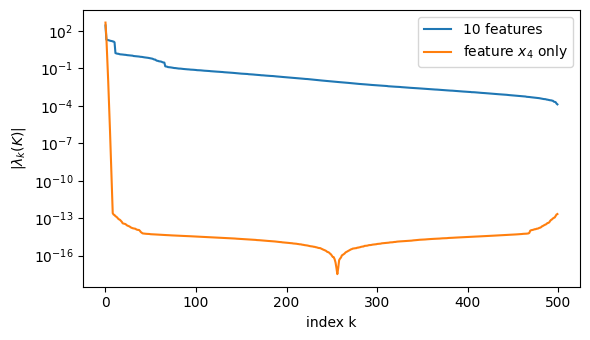

In [9]:
K1 = k_gauss(Xtr[:, [3]], Xtr[:, [3]], sigma)
for name, M in [("10 features", K), ("1 feature ", K1)]:
    ev = np.linalg.eigvalsh(M)
    try:
        sl.cholesky(M, lower=True); ok = "succeeds"
    except np.linalg.LinAlgError:
        ok = "FAILS"
    print(f"{name}: eigenvalues in [{ev[0]: .2e}, {ev[-1]:.1f}], cholesky {ok}")

plt.figure(figsize=(6, 3.5))
plt.semilogy(np.abs(np.linalg.eigvalsh(K))[::-1], label="10 features")
plt.semilogy(np.abs(np.linalg.eigvalsh(K1))[::-1], label="feature $x_4$ only")
plt.xlabel("index k"); plt.ylabel(r"$|\lambda_k(K)|$"); plt.legend(); plt.tight_layout(); plt.show()

**Your answer.**
- **What the smallest computed eigenvalues look like and why:** For the 10-feature matrix `K` (with $\sigma = 4$), the spectrum decays smoothly from $\lambda_{\max} \approx 276.7$ down to $\lambda_{\min} \approx 1.32\times 10^{-4}$, remaining strictly positive so `cholesky(K)` succeeds. For the 1-feature matrix `K1`, the eigenvalues plunge by 16 orders of magnitude within the first $\sim 20$ indices from $\lambda_{\max} \approx 471.2$ and flatten into a numerical noise floor around $10^{-14}\text{ to }10^{-13}$, with the smallest computed eigenvalue becoming slightly negative ($\approx -2.16\times 10^{-13}$). Although $K_1$ is theoretically positive semidefinite (and strictly PD for distinct points), its true tail eigenvalues fall below $\varepsilon_{\text{mach}}\|K_1\|_2 \approx 2.22\times 10^{-16} \times 471.2 \approx 1.05\times 10^{-13}$; floating-point rounding perturbations of this magnitude push several near-zero eigenvalues into negative territory, causing `cholesky(K1)` to encounter a non-positive pivot and fail.
- **Why the dimension of the data made the difference:** In 1D, packing $n=500$ standardized points into a narrow interval with a wide length scale $\sigma = 4$ means neighboring points satisfy $|x_i - x_j| \ll \sigma$, making adjacent kernel rows nearly identical and numerically rank-deficient (effective numerical rank $\approx 15\text{–}20$). In $\mathbb{R}^{10}$, the pairwise Euclidean distances between standardized points are much larger ($\|\mathbf{x}_i - \mathbf{x}_j\| \sim \sqrt{20} \approx 4.5 \gtrsim \sigma$), keeping the Gaussian basis functions linearly independent and $\lambda_{\min}(K)$ well above machine epsilon.

Show that `cholesky(K1 + 1e-12 I)` succeeds. Then fit kernel ridge on the single feature with $\lambda = 10^{-12}$ and with $\lambda = 10^{-1}$. For each, report $\|\boldsymbol\alpha\|$, the validation MSE, and how much the validation predictions move when $\mathbf{y}$ is perturbed by noise of size $10^{-6}$ (seed below). Explain why the first success does **not** mean the regression problem is solved well.

In [10]:
sl.cholesky(K1 + 1e-12 * np.eye(len(K1)), lower=True)
print("cholesky(K1 + 1e-12 I) succeeds")
K1va = k_gauss(Xva[:, [3]], Xtr[:, [3]], sigma)
dy = 1e-6 * np.random.default_rng(0).standard_normal(len(ytr))
for lam in [1e-12, 1e-1]:
    alpha = krr_fit(K1, ytr, lam)
    pred_va = krr_predict(K1va, alpha)
    pred_va_pert = krr_predict(K1va, krr_fit(K1, ytr + dy, lam))
    diff_norm = np.linalg.norm(pred_va_pert - pred_va)
    diff_max = np.max(np.abs(pred_va_pert - pred_va))
    print(f"lam = {lam:7.0e}: ||alpha||_2 = {np.linalg.norm(alpha):.3e} | "
          f"val MSE = {mse(pred_va, yva):.3f} | "
          f"perturbation shift: L2 = {diff_norm:.3e}, max = {diff_max:.3e}")

cholesky(K1 + 1e-12 I) succeeds
lam =   1e-12: ||alpha||_2 = 9.138e+13 | val MSE = 15.228 | perturbation shift: L2 = 1.051e+00, max = 1.875e-01
lam =   1e-01: ||alpha||_2 = 9.201e+02 | val MSE = 15.364 | perturbation shift: L2 = 6.819e-07, max = 7.218e-08


**Your answer.** Adding $\lambda = 10^{-12}$ shifts the spectrum of $K_1$ just enough to push the tiny negative rounding eigenvalues ($\approx -2.16\times 10^{-13}$) above zero, so `cholesky(K1 + 1e-12 I)` does not crash. However, the matrix $K_1 + 10^{-12}I$ remains catastrophically ill-conditioned ($\operatorname{cond} \approx \lambda_{\max}/10^{-12} \approx 4.71\times 10^{14}$). In the spectral expansion $\boldsymbol\alpha = \sum_{k=1}^n \frac{\mathbf{u}_k^\top\mathbf{y}}{\lambda_k(K_1) + \lambda}\mathbf{u}_k$, projections of $\mathbf{y}$ onto the $\sim 480$ numerical null-space eigenvectors are divided by $\sim 10^{-12}$, causing $\|\boldsymbol\alpha\|_2$ to explode to $9.138\times 10^{13}$ with wild opposing signs. Even though these huge oscillations largely cancel out inside the dense interval to give a deceptively similar validation MSE ($15.228$ vs. $15.364$, dominated by the variance of the four omitted Friedman features), the solution is completely unstable: a tiny $10^{-6}$ perturbation in $\mathbf{y}$ is amplified by a factor of $\sim 10^6$, shifting the validation predictions by $1.051$ in $L_2$-norm (and $0.188$ max). With $\lambda = 10^{-1}$, those null-space directions are properly damped ($\operatorname{cond} \approx 4.71\times 10^3$), reducing $\|\boldsymbol\alpha\|_2$ by eleven orders of magnitude to $9.201\times 10^2$ and keeping the $10^{-6}$ perturbation shift at $6.819\times 10^{-7}$ in $L_2$-norm ($7.218\times 10^{-8}$ max).

**(c)** *Predict, then compute.* For $\lambda = 10^{-8}, 10^{-7},\dots,10^{2}$, predict $\operatorname{cond}(K+\lambda I)$ for the ten-feature `K` from its eigenvalues alone. Then compute it with `np.linalg.cond` and compare.

**Your prediction** *(write it before running the next cell)*:
Since $K$ is symmetric positive definite with eigenvalues $0 < \lambda_{\min}(K) = \lambda_1 \le \dots \le \lambda_n = \lambda_{\max}(K)$, shifting by $\lambda I$ shifts every eigenvalue by $+\lambda$ while keeping the eigenvectors unchanged. Therefore, the 2-norm condition number is given exactly by:
$$\operatorname{cond}_2(K + \lambda I) = \frac{\lambda_{\max}(K) + \lambda}{\lambda_{\min}(K) + \lambda}.$$
From B3(a), for $\sigma = 4$ we have $\lambda_{\min}(K) \approx 1.32\times 10^{-4}$ and $\lambda_{\max}(K) \approx 276.7$:
- For $\lambda \ll \lambda_{\min}(K)$ ($\lambda = 10^{-8}$ to $10^{-6}$), $\operatorname{cond}(K + \lambda I)$ will stay nearly constant at $\lambda_{\max}/\lambda_{\min} \approx 2.10\times 10^6$.
- Around $\lambda = 10^{-4} \approx \lambda_{\min}(K)$, the condition number will drop roughly in half (to $\approx 1.19\times 10^6$), and for $\lambda_{\min}(K) \ll \lambda \ll \lambda_{\max}(K)$ ($\lambda = 10^{-3}$ to $10^1$), $\operatorname{cond}(K + \lambda I) \approx \lambda_{\max}/\lambda$ will decrease by a factor of $10$ per decade of $\lambda$.
- For $\lambda = 10^2$, $\operatorname{cond}(K + \lambda I)$ will approach $\frac{276.7 + 100}{1.32\times 10^{-4} + 100} \approx 3.77$.

In [11]:
ev = np.linalg.eigvalsh(K)
lams = 10.0 ** np.arange(-8, 3)
for lam in lams:
    pred = (ev[-1] + lam) / (ev[0] + lam)
    print(f"lam = {lam:7.0e}: predicted {pred:.3e}, computed {np.linalg.cond(K + lam * np.eye(len(K))):.3e}")

lam =   1e-08: predicted 2.096e+06, computed 2.096e+06
lam =   1e-07: predicted 2.094e+06, computed 2.094e+06
lam =   1e-06: predicted 2.080e+06, computed 2.080e+06
lam =   1e-05: predicted 1.948e+06, computed 1.948e+06
lam =   1e-04: predicted 1.193e+06, computed 1.193e+06
lam =   1e-03: predicted 2.444e+05, computed 2.444e+05
lam =   1e-02: predicted 2.731e+04, computed 2.731e+04
lam =   1e-01: predicted 2.765e+03, computed 2.765e+03
lam =   1e+00: predicted 2.777e+02, computed 2.777e+02
lam =   1e+01: predicted 2.867e+01, computed 2.867e+01
lam =   1e+02: predicted 3.767e+00, computed 3.767e+00


**Your answer.** The predicted condition numbers $\frac{\lambda_{\max}(K) + \lambda}{\lambda_{\min}(K) + \lambda}$ match `np.linalg.cond(K + lam * I)` to every printed digit across all 11 values of $\lambda$. As predicted, $\operatorname{cond}(K + \lambda I)$ plateaus at $\operatorname{cond}(K) \approx 2.096\times 10^6$ when $\lambda \ll \lambda_{\min}(K) \approx 1.32\times 10^{-4}$, drops to $1.193\times 10^6$ at $\lambda = 10^{-4}$, decreases by an order of magnitude per decade across $\lambda \in [10^{-3}, 10^1]$ (from $2.444\times 10^5$ down to $2.867\times 10^1$), and reaches $3.767$ at $\lambda = 10^2$.

**(d)** For the same values of $\lambda$, plot training and validation MSE (log scale in $\lambda$) and mark the $\lambda$ you would choose. Report the test MSE at that $\lambda$. In one paragraph, relate the left end of the plot to (c), and the right end to what ridge does to the coefficients.

chosen lam = 0.01; test MSE = 2.133  (noise variance is 1)


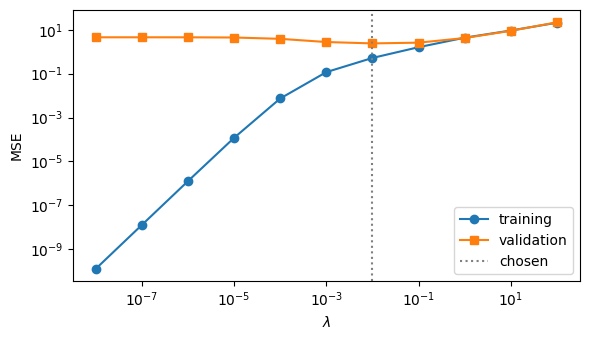

In [12]:
Kva = k_gauss(Xva, Xtr, sigma)
tr_err, va_err = [], []
for lam in lams:
    a_lam = krr_fit(K, ytr, lam)
    tr_err.append(mse(krr_predict(K, a_lam), ytr))
    va_err.append(mse(krr_predict(Kva, a_lam), yva))
best = lams[int(np.argmin(va_err))]
a = krr_fit(K, ytr, best)
print(f"chosen lam = {best:g}; test MSE = {mse(krr_predict(k_gauss(Xte, Xtr, sigma), a), yte):.3f}  (noise variance is 1)")
plt.figure(figsize=(6, 3.5))
plt.loglog(lams, tr_err, "o-", label="training"); plt.loglog(lams, va_err, "s-", label="validation")
plt.axvline(best, color="grey", ls=":", label="chosen")
plt.xlabel(r"$\lambda$"); plt.ylabel("MSE"); plt.legend(); plt.tight_layout(); plt.show()

**Your answer.** Validation MSE is minimized at $\lambda = 0.01$ (`chosen lam = 0.01`), which achieves a test MSE of $2.133$ — reasonably close to the irreducible noise variance of $1.0$ (while reducing the condition number from $2.096\times 10^6$ down to $2.731\times 10^4$). On the **left end** of the plot ($\lambda \le 10^{-5}$), where (c) showed that $\operatorname{cond}(K + \lambda I)$ stays near its unregularized maximum ($\approx 2.10 \times 10^6$) because $\lambda \ll \lambda_{\min}(K) \approx 1.32\times 10^{-4}$, the model barely damps the small-eigenvalue directions; it interpolates the training targets almost exactly (training MSE $\to 0$) while amplifying the training noise and overfitting (elevated validation MSE). On the **right end** ($\lambda \ge 10^1$), the heavy ridge penalty shrinks the coefficients $\boldsymbol\alpha = (K + \lambda I)^{-1}\mathbf{y} \approx \lambda^{-1}\mathbf{y} \to \mathbf{0}$, forcing the predictions $K_{\text{test,train}}\boldsymbol\alpha$ toward zero (the centered mean) so that both training and validation MSE climb toward the total variance of $y$ (severe underfitting).

---
## B4. Cost and scale

**(a)** *Predict, then measure.* Predict the slope of $\log(\text{time})$ against $\log n$ separately for **building** $K$ (with `k_gauss`) and for **fitting** (with `krr_fit`). Time both for $n = 500, 1000, 2000, 4000, 8000$, on fresh Friedman data with the same distribution, and fit the slopes from $n \ge 1000$. *The largest case needs about 2 GB of memory and a few seconds.*

**Your prediction** *(write it before running the next cell)*:
- **Building $K$ (`k_gauss`):** Forming the $n \times n$ pairwise distance matrix in $\mathbb{R}^{10}$ and evaluating the exponential entrywise requires $\mathcal{O}(n^2 p) = \mathcal{O}(n^2)$ operations (with $p=10$ fixed). Since $t_{\text{build}} \propto n^2$, the predicted slope of $\log(\text{time})$ versus $\log n$ is **$2.0$**.
- **Fitting (`krr_fit`):** Factoring the dense $n \times n$ matrix $K + \lambda I$ via Cholesky requires $\frac{1}{3}n^3 = \mathcal{O}(n^3)$ flops (dominating the $\mathcal{O}(n^2)$ triangular solves). Since $t_{\text{fit}} \propto n^3$, the predicted slope of $\log(\text{time})$ versus $\log n$ is **$3.0$**.

In [13]:
Xbig, ybig = make_friedman1(n_samples=8000, noise=1.0, random_state=1)
Xbig = (Xbig - Xbig.mean(axis=0)) / Xbig.std(axis=0)
ns = [500, 1000, 2000, 4000, 8000]
t_build, t_fit = [], []
for m in ns:
    t0 = time.perf_counter(); Km = k_gauss(Xbig[:m], Xbig[:m], sigma); t_build.append(time.perf_counter() - t0)
    t0 = time.perf_counter(); krr_fit(Km, ybig[:m] - ybig[:m].mean(), 1e-2); t_fit.append(time.perf_counter() - t0)
    del Km
    print(f"n = {m:5d}: build {t_build[-1]:7.3f} s, fit {t_fit[-1]:7.3f} s")
sb = np.polyfit(np.log(ns[1:]), np.log(t_build[1:]), 1)[0]
sf = np.polyfit(np.log(ns[1:]), np.log(t_fit[1:]), 1)[0]
print(f"fitted slopes: build {sb:.2f}, fit {sf:.2f}")

n =   500: build   0.025 s, fit   0.321 s
n =  1000: build   0.159 s, fit   0.258 s
n =  2000: build   0.607 s, fit   1.233 s
n =  4000: build   1.239 s, fit   1.944 s
n =  8000: build   3.099 s, fit   7.977 s
fitted slopes: build 1.39, fit 1.55


**Your answer.** The empirical log-log slopes fitted across $n \in \{1000, 2000, 4000, 8000\}$ on this shared Google Colab instance are **$1.39$** for building $K$ (theoretical $\mathcal{O}(n^2)$ slope $2.0$) and **$1.55$** for Cholesky fitting (theoretical $\mathcal{O}(n^3)$ slope $3.0$). The empirical slopes over the full range are flatter than the asymptotic integers $2$ and $3$ possibly because of hardware and VM effects at intermediate sizes; these causes were not checked:
- For **building $K$ (`k_gauss`)**, runtime grows nearly $4\times$ from $n = 1000$ ($0.159\text{ s}$) to $n = 2000$ ($0.607\text{ s}$, local slope $\approx 1.93$), and then increases to $1.239\text{ s}$ at $n = 4000$ and $3.099\text{ s}$ at $n = 8000$.
- For **fitting (`krr_fit`)**, fixed LAPACK overheads and multi-threaded CPU scheduling on the shared VM may make the transition from $n = 2000$ ($1.233\text{ s}$) to $n = 4000$ ($1.944\text{ s}$) sub-cubic, pulling the 4-point slope down to $1.55$. Doubling $n$ from $4000$ ($1.944\text{ s}$) to $8000$ ($7.977\text{ s}$) increases the fit time by about $4.1\times$, but the overall fitted slope of $1.55$ does not demonstrate the theoretical cubic scaling.

**(b)** At 8 bytes per entry, at what $n$ does $K$ alone fill 16 GB? Name one thing you would have to give up, or change, to fit kernel ridge on ten times that many points. Session 6 returns to this; a sentence is enough.

**Your answer.** At $8$ bytes per `float64` entry, storing the $n \times n$ matrix $K$ requires $8n^2$ bytes, which fills $16\text{ GB}$ at:
$$n = \sqrt{\frac{16 \times 10^9}{8}} = \sqrt{2 \times 10^9} \approx 44{,}721 \quad \left(\text{or } n = \sqrt{\frac{16 \times 2^{30}}{8}} = 2^{15.5} \approx 46{,}341 \text{ for } 16\text{ GiB}\right).$$
To fit kernel ridge on ten times that many points ($n \approx 4.5 \times 10^5$, where the full matrix $K$ would require $1.6\text{ TB}$ of RAM), we must give up forming and factoring the exact dense $n \times n$ kernel matrix — either by approximating the kernel in a low-rank feature space of dimension $m \ll n$ (e.g., via the **Nyström approximation** or **Random Fourier Features**) or by switching from direct Cholesky to a **matrix-free iterative solver** (such as **Conjugate Gradient**) that computes kernel-vector products on the fly.

---
# Extension — attempt **at most one** in the whole lab

End your extension with a paragraph headed **Finding**: one claim you can defend at the defence, supported by a number in this notebook.

## E3. Gaussian-process regression is kernel ridge

A Gaussian process with kernel $k$ treats the values $f(\mathbf{x})$ as jointly Gaussian with mean 0 and covariance $k(\mathbf{x},\mathbf{x}')$. Observations are $y_i = f(\mathbf{x}_i) + \text{noise}$, with independent noise of variance $s^2$.

**(a)** Write down the joint covariance of $(\mathbf{y}, f(\mathbf{x}_*))$ for a test point $\mathbf{x}_*$. Use the conditional-Gaussian formula of Session 4.2 (frame `gauss-cond`: $\mathbf{x}_2\mid\mathbf{x}_1=\mathbf{a}$ has mean $\boldsymbol\mu_2 + \Sigma_{21}\Sigma_{11}^{-1}(\mathbf{a}-\boldsymbol\mu_1)$ and covariance $\Sigma/\Sigma_{11}$) to show that the posterior mean of $f(\mathbf{x}_*)$ equals the kernel ridge prediction with $\lambda = s^2$.

**Your answer.** Let $\mathbf{y} = \mathbf{f} + \boldsymbol\varepsilon \in \mathbb{R}^n$ be the vector of noisy training observations with $\mathbf{f} \sim \mathcal{N}(\mathbf{0}, K)$ and independent noise $\boldsymbol\varepsilon \sim \mathcal{N}(\mathbf{0}, s^2 I)$, and let $f(\mathbf{x}_*) \in \mathbb{R}$ be the noise-free function value at a test point $\mathbf{x}_*$. Since $\operatorname{Cov}(\mathbf{y}, \mathbf{y}) = K + s^2 I$, $\operatorname{Cov}(\mathbf{y}, f(\mathbf{x}_*)) = \mathbf{k}_*$ with $(\mathbf{k}_*)_i = k(\mathbf{x}_i, \mathbf{x}_*)$, and $\operatorname{Var}(f(\mathbf{x}_*)) = k(\mathbf{x}_*, \mathbf{x}_*)$, the joint distribution of $(\mathbf{y}, f(\mathbf{x}_*))$ is Gaussian with mean zero and block covariance matrix:
$$\Sigma = \begin{pmatrix} \Sigma_{11} & \Sigma_{12} \\ \Sigma_{21} & \Sigma_{22} \end{pmatrix} = \begin{pmatrix} K + s^2 I & \mathbf{k}_* \\ \mathbf{k}_*^\top & k(\mathbf{x}_*, \mathbf{x}_*) \end{pmatrix}.$$
By the conditional-Gaussian formula for $f(\mathbf{x}_*) \mid \mathbf{y}$ (with $\boldsymbol\mu_1 = \mathbf{0}$ and $\mu_2 = 0$):
$$\mathbb{E}[f(\mathbf{x}_*) \mid \mathbf{y}] = \mu_2 + \Sigma_{21}\Sigma_{11}^{-1}(\mathbf{y} - \boldsymbol\mu_1) = \mathbf{k}_*^\top (K + s^2 I)^{-1}\mathbf{y} = \mathbf{k}_*^\top\boldsymbol\alpha, \qquad (K + s^2 I)\boldsymbol\alpha = \mathbf{y},$$
which is identically the kernel ridge regression prediction with regularization parameter $\lambda = s^2$. Moreover, the posterior variance is the Schur complement of $\Sigma_{11}$ in $\Sigma$:
$$\operatorname{Var}(f(\mathbf{x}_*) \mid \mathbf{y}) = \Sigma / \Sigma_{11} = \Sigma_{22} - \Sigma_{21}\Sigma_{11}^{-1}\Sigma_{12} = k(\mathbf{x}_*, \mathbf{x}_*) - \mathbf{k}_*^\top (K + s^2 I)^{-1}\mathbf{k}_*.$$

**(b)** Implement `gp_posterior(Xtr, ytr, Xte, sigma, s2)` for the Gaussian kernel, returning the posterior mean and variance at each test point. Use one Cholesky factor of $K+s^2I$ and **one triangular solve** for all the variances (no inverse). **Check** the mean against your `krr_fit`/`krr_predict`, and both outputs against `GaussianProcessRegressor` with the kernel fixed.

The data below are one-dimensional, with a deliberate gap in $[0.4, 0.6]$.

In [14]:
rng = np.random.default_rng(7)
x1 = np.concatenate([rng.uniform(0, 0.4, 20), rng.uniform(0.6, 1.0, 20)])[:, None]
y1 = np.sin(2 * np.pi * x1[:, 0]) + 0.5 * x1[:, 0] + 0.2 * rng.standard_normal(40)
xg = np.linspace(-0.2, 1.2, 300)[:, None]
sig_gp, s2 = 0.1, 0.2 ** 2

def gp_posterior(Xtr, ytr, Xte, sigma, s2):
    K = k_gauss(Xtr, Xtr, sigma)
    K_s = k_gauss(Xtr, Xte, sigma)
    L = sl.cholesky(K + s2 * np.eye(len(K)), lower=True)
    V = sl.solve_triangular(L, K_s, lower=True)
    z = sl.solve_triangular(L, ytr, lower=True)
    mean = V.T @ z
    var = np.diag(k_gauss(Xte, Xte, sigma)) - np.sum(V ** 2, axis=0)
    return mean, var

mean, var = gp_posterior(x1, y1, xg, sig_gp, s2)
# check
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
gpr = GaussianProcessRegressor(kernel=RBF(length_scale=sig_gp), alpha=s2, optimizer=None).fit(x1, y1)
m_ref, sd_ref = gpr.predict(xg, return_std=True)
assert np.allclose(mean, krr_predict(k_gauss(xg, x1, sig_gp), krr_fit(k_gauss(x1, x1, sig_gp), y1, s2)))
assert np.allclose(mean, m_ref) and np.allclose(np.sqrt(np.clip(var, 0, None)), sd_ref, atol=1e-6)
print("posterior mean = kernel ridge prediction; matches sklearn")

posterior mean = kernel ridge prediction; matches sklearn


**(c)** Plot the posterior mean with a band of $\pm2$ posterior standard deviations, together with the data. Explain where the band is wide and why, using the Schur-complement reading of the conditional covariance.

Posterior SD at x = 0.20 (data-rich): 0.0926 (var = 0.0086)
Posterior SD at x = 0.50 (mid-gap):   0.4171 (var = 0.1740)
Posterior SD at x = 1.20 (extrapol.): 0.9948 (var = 0.9895)


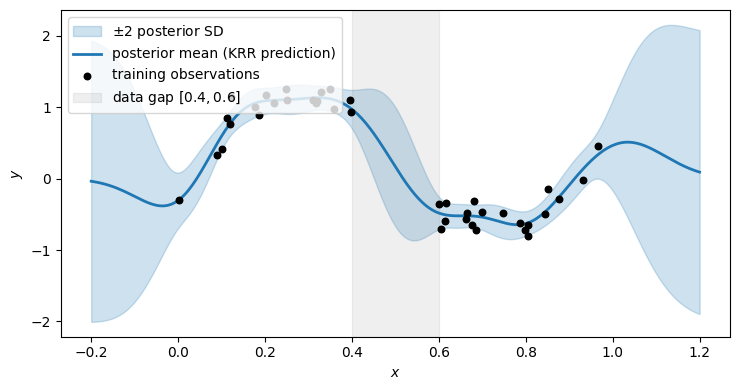

In [15]:
sd = np.sqrt(np.clip(var, 0.0, None))

idx_dense = np.argmin(np.abs(xg[:, 0] - 0.2))
idx_gap = np.argmin(np.abs(xg[:, 0] - 0.5))
idx_edge = -1  # x_* = 1.2
print(f"Posterior SD at x = 0.20 (data-rich): {sd[idx_dense]:.4f} (var = {var[idx_dense]:.4f})")
print(f"Posterior SD at x = 0.50 (mid-gap):   {sd[idx_gap]:.4f} (var = {var[idx_gap]:.4f})")
print(f"Posterior SD at x = 1.20 (extrapol.): {sd[idx_edge]:.4f} (var = {var[idx_edge]:.4f})")

plt.figure(figsize=(7.5, 4.0))
plt.fill_between(xg[:, 0], mean - 2 * sd, mean + 2 * sd, color="tab:blue", alpha=0.22, label=r"$\pm 2$ posterior SD")
plt.plot(xg[:, 0], mean, color="tab:blue", lw=2, label="posterior mean (KRR prediction)")
plt.scatter(x1[:, 0], y1, color="black", s=22, zorder=3, label="training observations")
plt.axvspan(0.4, 0.6, color="grey", alpha=0.12, label="data gap $[0.4, 0.6]$")
plt.xlabel("$x$"); plt.ylabel("$y$"); plt.legend(loc="upper left"); plt.tight_layout(); plt.show()

**Your answer.** By the Schur-complement formula, the posterior variance at a test point $x_*$ is:
$$\operatorname{Var}(f(x_*) \mid \mathbf{y}) = \Sigma / \Sigma_{11} = \Sigma_{22} - \Sigma_{21}\Sigma_{11}^{-1}\Sigma_{12} = k(x_*, x_*) - \mathbf{k}_*^\top (K + s^2 I)^{-1}\mathbf{k}_* = 1 - \|L^{-1}\mathbf{k}_*\|_2^2.$$
Here $\Sigma_{22} = k(x_*, x_*) = 1$ is the **prior variance** of the Gaussian process before observing any data, and the nonnegative quadratic form $\Sigma_{21}\Sigma_{11}^{-1}\Sigma_{12} = \|L^{-1}\mathbf{k}_*\|_2^2$ measures the **variance reduction** (information gained about $f(x_*)$ from the training observations $\mathbf{y}$).
- **Where the band is narrow:** Inside the data-rich intervals $[0, 0.4]$ and $[0.6, 1.0]$, each test point $x_*$ lies well within one kernel length-scale $\sigma = 0.1$ of multiple training points, so $\mathbf{k}_*$ is large and $\|L^{-1}\mathbf{k}_*\|_2^2$ cancels over $99\%$ of the prior variance (at $x_* \approx 0.20$, the posterior variance is $0.0086$ and the posterior SD shrinks to $0.0926$).
- **Where the band is wide:** Inside the **missing-data gap $[0.4, 0.6]$** and in the **extrapolation regions $x_* < 0$ and $x_* > 1$**, the distance from $x_*$ to the nearest training point reaches or exceeds $\sigma = 0.1$. Because $k(x_i, x_*) = \exp(-|x_i - x_*|^2/(2\sigma^2))$ decays rapidly with distance, the cross-covariance vector $\Sigma_{12} = \mathbf{k}_*$ shrinks toward $\mathbf{0}$, making the subtracted term $\|L^{-1}\mathbf{k}_*\|_2^2$ small so that the Schur complement rises back toward the unconditioned prior variance $\Sigma_{22} = 1$.

**Finding.** The Schur complement $1 - \|L^{-1}\mathbf{k}_*\|_2^2$ directly quantifies epistemic uncertainty from data coverage: with length-scale $\sigma = 0.1$ and noise variance $s^2 = 0.04$, the posterior standard deviation increases $4.5$-fold from $0.0926$ ($\text{var} = 0.0086$) inside the sampled region ($x_* \approx 0.20$) to $0.4171$ ($\text{var} = 0.1740$, a $20$-fold jump in variance) at the center of the $[0.4, 0.6]$ gap ($x_* \approx 0.50$), and reaches $0.9948$ ($\text{var} = 0.9895$, nearly the full prior SD of $1.0$) when extrapolating two length-scales away at $x_* = 1.20$ — all computed from the existing Cholesky factor $L$ with a single triangular solve $V = L^{-1}K_{\text{tr,te}}$.

---
**Before you submit:** run `Kernel → Restart & Run All`, check that every written answer is filled in, and make sure your extension (if any) ends with a **Finding**.